## Задание 1: Постраничная загрузка и сортировка продуктов

Выполнил: Ларюшкин Кирилл Александрович

Группа : 292605


```bash
python -m venv venv
venv\Scripts\activate
pip install requests
pip freeze > requirements.txt
```

In [ ]:
import requests  # Импорт модуля requests
import logging  # Импорт модуля logging


# Настройка логирования
logging.basicConfig(
    filename='task1.log',  # Файл куда сохранять логи
    filemode='w',  # Режим - перезаписывать файл с логами при запуске
    level=logging.DEBUG,  # Определениение уровня логирования - уровень логирования DEBUG и выше
    format='%(asctime)s - %(levelname)s - %(message)s',  # Формат логов
    encoding='UTF-8',  # Кодировка UTF-8 , для корректного отображения кириллицы 
)


def get_products(params: dict):
    """ Функция принимает на вход параметры запроса
    Выполняет get запрос к API, получает данные по 10 продуктам, пропуская первые 10, сортирует по цене и убыванию
    Выводит название продуктов и их цены
    """
    
    try:
        logging.info('Отправка запроса к API...')  # Логирование с информацией об отправке запроса
        response = requests.get('https://dummyjson.com/products', params=params, timeout=10)  # GET запрос к API https://dummyjson.com/products, с передачей параметров params и временем тайм-аута, что бы вечно не ждать ответа .а выхывать исключение
        response.raise_for_status()  # Контроль статус-кода ответа, вызывает исключение если HTTP вернет ошибку
    
        logging.info(f'Статус-код ответа: {response.status_code}')  # Логирование статус-кода ответа
    
        data = response.json()  # Преобразование JSON в словарь, т.е в обьект Python
        products = data.get('products', [])  # Получает словарь продуктов 'products' из словаря data, если ключа 'products' нет, возвращает пустой список []

        # Цикл, который проходит по каждому продукту из словаря products и выводит на экран его название и цену
        for product in products:
                 print(f'- {product["title"]}: ${product["price"]}')  # Вывод на экран продукта в формате "- Название: $Цена"
            
    # Обработка исключений
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        print(f'Произошла ошибка HTTP : {e}')
        logging.error(f'Произошла ошибка HTTP:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы  

    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        print(f'Произошла ошибка: {e}')  # Вывод ошибки на экран
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы
        
    except TypeError as e:  # Обрабатывает ошибки при обработки данных
        print(f'Ошибка типа данных:{e}')  # Выводит ошибку на экран
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        exit()  # Прекращает выполнение программы


# Параметры запроса
params = {
         'limit': 10,  # Лимит, сколько максимум товаров брать
         'skip': 10,  # Сколько товаров пропустить после сортировки
         'sortBy': 'price', # Сортировка по цене
         'order': 'desc' # Соритровка по убыванию
     }

get_products(params)  # Вызов функции с передачей словаря с параметрами в качестве аргумента

- Rolex Datejust Women: $10999.99
- Rolex Cellini Date Black Dial: $8999.99
- Kawasaki Z800: $8999.99
- Sportbike Motorcycle: $7499.99
- IWC Ingenieur Automatic Steel: $4999.99
- Generic Motorcycle: $3999.99
- Scooter Motorcycle: $2999.99
- Annibale Colombo Sofa: $2499.99
- Apple MacBook Pro 14 Inch Space Grey: $1999.99
- Annibale Colombo Bed: $1899.99


```bash
deactivate
```

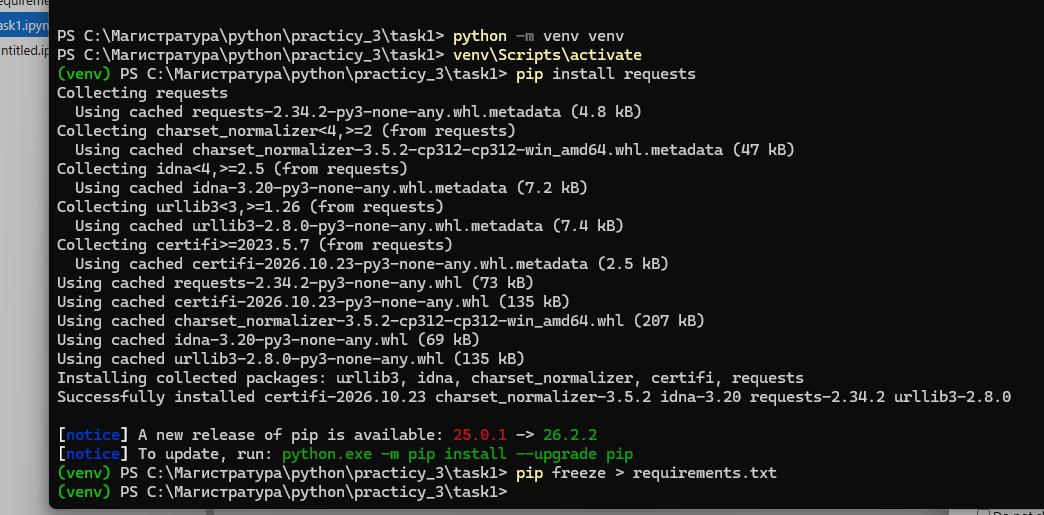

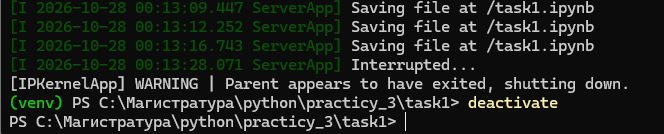